# Malware Classification using Machine Learning (PE Header Features)
**IBM SkillsBuild Cyber Security BootCamp 2026 | BharatCares**

**Goal:** classify Windows executables (PE files) as *benign* or *malware* using only static features taken from the PE header, with no need to run the file.

**Dataset:** ClaMP (Classification of Malware with PE headers), Kumar, A. (2020), Mendeley Data, DOI 10.17632/xvyv59vwvz.1. Also on Kaggle as *Classification of Malwares (CLaMP)* by saurabhshahane.
Use the file `ClaMP_Integrated-5184.csv`. Target column: `class` (0 = benign, 1 = malware).

**How to run:** download the CSV, place it next to this notebook (or change `DATA_PATH` below), then choose **Kernel > Restart & Run All**.

## 1. Import libraries

In [36]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


## 2. Load the dataset

In [37]:
import os
# Download the CLaMP dataset if it doesn't already exist
if not os.path.exists('ClaMP_Integrated-5184.csv'):
    !wget -q https://raw.githubusercontent.com/saurabhshahane/Classification-of-Malwares/main/ClaMP_Integrated-5184.csv
    print('Dataset downloaded successfully.')
else:
    print('Dataset already exists.')

Dataset already exists.


**File path note:** `DATA_PATH` below points to the CSV in the same folder as the notebook. In Google Colab that folder is `/content/`, so upload the CSV there (or let the download cell above fetch it).

In [38]:
DATA_PATH = 'ClaMP_Integrated-5184.csv'  # same folder as the notebook (in Colab: /content/)
TARGET = 'class'

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
display(df.head())

Shape: (5210, 70)


,e_cblp,e_cp,e_cparhdr,e_maxalloc,e_sp,e_lfanew,NumberOfSections,CreationYear,FH_char0,FH_char1,...,sus_sections,non_sus_sections,packer,packer_type,E_text,E_data,filesize,E_file,fileinfo,class
0,144,3,4,65535,184,256,4,1,0,1,...,1,3,0,NoPacker,6.603616,5.443362,1181520,6.627552,1,0
1,144,3,4,65535,184,184,4,1,0,1,...,1,3,0,NoPacker,5.205926,2.123522,7680,5.318221,0,0
2,144,3,4,65535,184,272,5,1,0,1,...,1,4,0,NoPacker,6.238000,3.380859,57872,6.507758,1,0
3,144,3,4,65535,184,184,1,1,0,1,...,0,1,0,NoPacker,0.000000,0.000000,95616,4.575092,1,0
4,144,3,4,65535,184,224,5,1,0,1,...,1,4,0,NoPacker,6.355626,0.702621,48128,5.545531,1,0


## 3. Explore the data

In [39]:
print("Rows, columns:", df.shape)
print("\nMissing values in total:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nData types:")
print(df.dtypes.value_counts())
df.describe().T.head(15)

Rows, columns: (5210, 70)

Missing values in total: 0
Duplicate rows: 3

Data types:
int64      66
float64     3
object      1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
e_cblp,5210.0,152.658733,616.499070,0.0,144.0,144.0,144.0,37008.0
e_cp,5210.0,10.633589,392.745064,0.0,3.0,3.0,3.0,20050.0
e_cparhdr,5210.0,8.903263,251.685103,0.0,4.0,4.0,4.0,12851.0
e_maxalloc,5210.0,65137.618234,5005.606042,0.0,65535.0,65535.0,65535.0,65535.0
e_sp,5210.0,202.530902,968.625098,0.0,184.0,184.0,184.0,65534.0
e_lfanew,5210.0,222.833013,48.591497,12.0,208.0,232.0,248.0,648.0
NumberOfSections,5210.0,4.662956,1.922882,1.0,4.0,5.0,5.0,34.0
CreationYear,5210.0,0.990403,0.097502,0.0,1.0,1.0,1.0,1.0
FH_char0,5210.0,0.362764,0.480844,0.0,0.0,0.0,1.0,1.0
FH_char1,5210.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


class
0    2488
1    2722
Name: count, dtype: int64


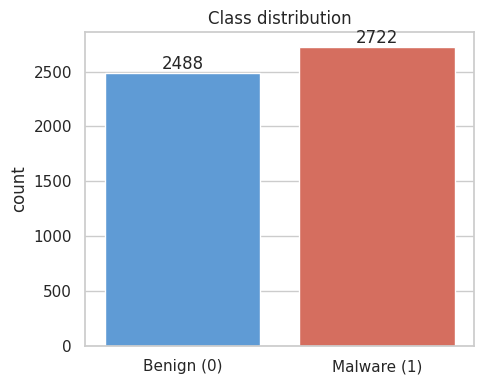

In [40]:
counts = df[TARGET].value_counts().sort_index()
print(counts)

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=TARGET, data=df, palette=["#4c9be8", "#e8604c"])
ax.set_xticklabels(["Benign (0)", "Malware (1)"])
ax.set_title("Class distribution")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

## 4. Preprocessing
We remove duplicate rows, keep numeric columns only, and fill any missing values with the column median.

In [41]:
data = df.drop_duplicates().copy()

# Keep only numeric feature columns (text columns such as hashes or names are not usable as-is)
non_numeric = [c for c in data.columns if c != TARGET and not pd.api.types.is_numeric_dtype(data[c])]
print("Dropped non-numeric columns:", non_numeric)
data = data.drop(columns=non_numeric)

# Median imputation for any missing values
data = data.fillna(data.median(numeric_only=True))

X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int)
print("Features:", X.shape[1], "| Samples:", X.shape[0])

Dropped non-numeric columns: ['packer_type']
Features: 68 | Samples: 5207


In [42]:
# Drop constant columns because they carry no information
constant_cols = [c for c in X.columns if X[c].nunique() <= 1]
print("Constant columns removed:", constant_cols)
X = X.drop(columns=constant_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Constant columns removed: ['FH_char1', 'FH_char11', 'FH_char13', 'SectionAlignment', 'FileAlignment', 'OH_DLLchar5', 'OH_DLLchar6', 'OH_DLLchar10']
Train: (4165, 60) | Test: (1042, 60)


## 5. Train and compare models
Four classifiers are compared with 5-fold stratified cross-validation on the training set, then evaluated once on the held-out test set.

In [43]:
models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}

for name, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "CV Accuracy": cv_acc,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    fitted[name] = model

results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1", ascending=False)
results

,CV Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Random Forest,0.9902,0.9894,0.9890,0.9908,0.9899,0.9991
Gradient Boosting,0.9866,0.9846,0.9818,0.9890,0.9853,0.9988
Decision Tree,0.9745,0.9674,0.9636,0.9743,0.9689,0.9671
Logistic Regression,0.9582,0.9616,0.9667,0.9596,0.9631,0.9904


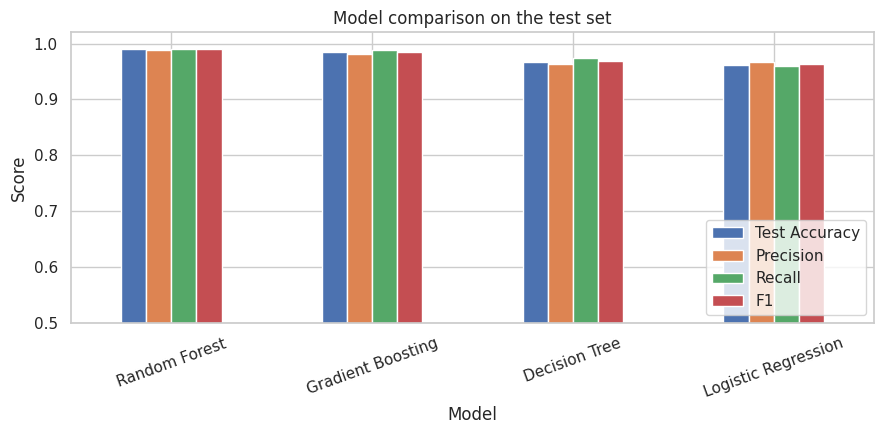

In [44]:
results[["Test Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4.5), ylim=(0.5, 1.02))
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## 6. Evaluate the best model

Best model (by F1): Random Forest
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99       498
     Malware       0.99      0.99      0.99       544

    accuracy                           0.99      1042
   macro avg       0.99      0.99      0.99      1042
weighted avg       0.99      0.99      0.99      1042



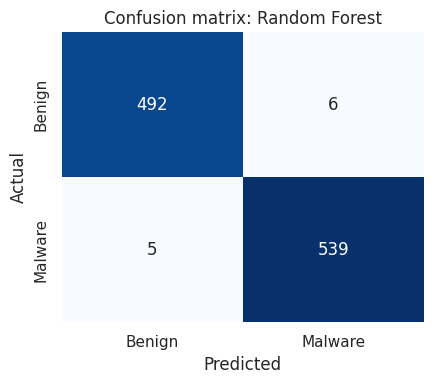

In [45]:
best_name = results.index[0]
best_model = fitted[best_name]
print("Best model (by F1):", best_name)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["Benign", "Malware"]))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Benign", "Malware"], yticklabels=["Benign", "Malware"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

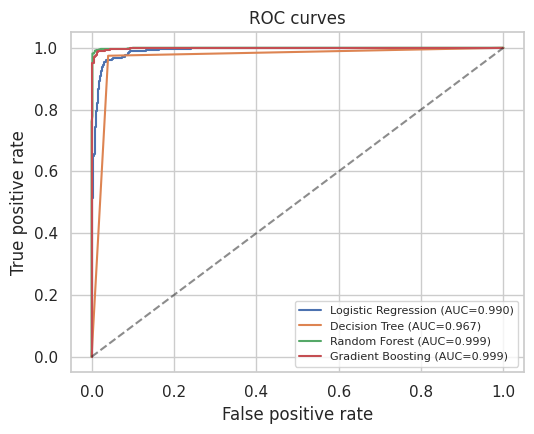

In [46]:
plt.figure(figsize=(5.5, 4.5))
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

## 7. Feature importance
Which PE header fields matter most for telling malware from benign files? Tree ensembles expose this directly.

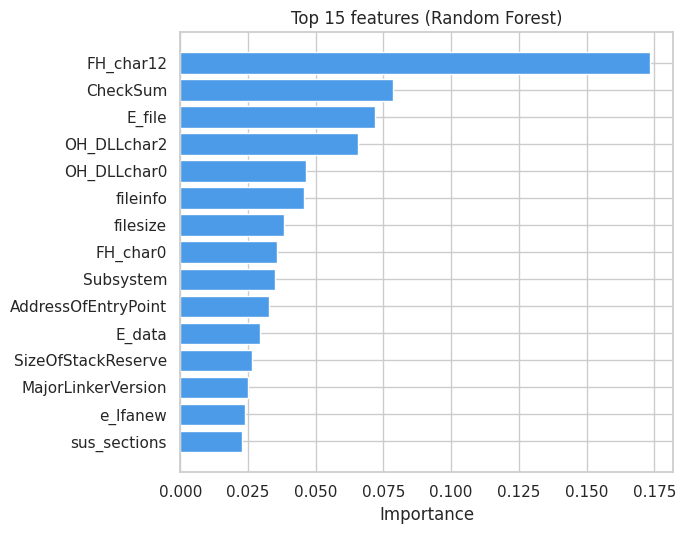

,0
FH_char12,0.173431
CheckSum,0.078570
E_file,0.071891
OH_DLLchar2,0.065430
OH_DLLchar0,0.046390
fileinfo,0.045556
filesize,0.038183
FH_char0,0.035518
Subsystem,0.034903
AddressOfEntryPoint,0.032676


In [47]:
rf = fitted["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

top = importances.head(15)[::-1]
plt.figure(figsize=(7, 5.5))
plt.barh(top.index, top.values, color="#4c9be8")
plt.title("Top 15 features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
importances.head(10)

## 8. Save the model and results

In [50]:
joblib.dump({"model": best_model, "features": list(X.columns), "name": best_name}, "malware_classifier.joblib")
results.to_csv("model_results.csv")
print("Saved: malware_classifier.joblib, model_results.csv and the PNG charts")

Saved: malware_classifier.joblib, model_results.csv and the PNG charts


In [51]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Not running in Colab: output files are saved in the current folder.')

# List of generated files to download
files_to_download = [
    'malware_classifier.joblib',
    'model_results.csv',
    'class_distribution.png',
    'model_comparison.png',
    'confusion_matrix.png',
    'roc_curves.png',
    'feature_importance.png'
]

if IN_COLAB:
    for file_name in files_to_download:
        if os.path.exists(file_name):
            print(f"Triggering download for: {file_name}")
            files.download(file_name)
        else:
            print(f"{file_name} not found.")

Triggering download for: malware_classifier.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggering download for: model_results.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggering download for: feature_importance.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Predict on a new sample
The saved model can score any row that has the same feature columns.

In [49]:
bundle = joblib.load("malware_classifier.joblib")
sample = X_test.iloc[[0]][bundle["features"]]
label = bundle["model"].predict(sample)[0]
prob = bundle["model"].predict_proba(sample)[0, 1]
print(f"Prediction: {'MALWARE' if label == 1 else 'BENIGN'}  (malware probability = {prob:.3f})")
print("Actual label:", 'MALWARE' if y_test.iloc[0] == 1 else 'BENIGN')

Prediction: MALWARE  (malware probability = 1.000)
Actual label: MALWARE


## 10. Conclusion
- PE header fields alone give strong static detection of malware, with no need to execute the file.
- Random Forest was the best model: test accuracy 0.9894, recall 0.9908, F1 0.9899 and ROC-AUC 0.9991. Gradient Boosting was close behind, and the single Decision Tree and Logistic Regression scored lower.
- On the 1,042 test files, Random Forest missed 5 malware files and wrongly flagged 6 benign files. The most important features were FH_char12, CheckSum, E_file, OH_DLLchar2 and OH_DLLchar0.
- **Limitations:** the dataset is fairly small, and features that can be changed easily (for example by packing or editing headers) may let malware evade the model.
- **Future work:** add API-call and DLL-import features, test on a newer and larger dataset, and tune hyperparameters.
